# Beispiel Konstruktion bestapproximierendes Element

Im Beispiel approximieren wir die Sinus Funktion mit Hilfe von Monome.

In [1]:
import sympy as sp
import numpy as np
from IPython.display import Math, display
import matplotlib.pyplot as plt
from sympy import pi

Als Funktionenraum benutzen wir den $L_2[-\pi,\pi]$ und suchen das bestapproximierende Element im Unterraum der Monome. Wenn wir nur eine endliche Anzahl Monome benutzen, z.B. mit maximalem Grad 5, so erhalten wir einen endlichdimensionalen Unterraum.

Das Skalarprodukt ist in dem Fall gegeben durch

$$(u,v)_{L_2} = \int_{-\pi}^{\pi} u(t) v(t) dt$$

daher

In [2]:
def dot(u,v):
    return sp.integrate(u*v,(t,-pi,pi))

wobei wir SymPy für die Computer Algebra benutzen.

Maximaler Grad der Monome:

In [3]:
n=5

In [4]:
t,k = sp.symbols('t k')

In [5]:
def x(t):
    return sp.sin(t)

Ziel ist es für $x(t) = \sin(t)$ das bestapproximierende Element $x_0\in V' = \text{span}\{x_1,\ldots,x_n\}$ zu finden.

In [6]:
basisset = np.array([t**i for i in range(n+1)])
basisset

array([1, t, t**2, t**3, t**4, t**5], dtype=object)

Mit $\lambda_k$, $k=1,\ldots, n$ bezeichnen wir die Koeffizienten der Linearkombination.

In [7]:
lam = sp.symbols('lambda:'+str(n+1))

Mit Hilfe der Gleichung (5.6) folgt das Gleichungssystem

$$(x(t), x_i(t))_{L_2} - \sum_{k=1}^n (x_k,x_i)_{L_2} = 0\quad \forall\ i = 1, \ldots, n$$

In [8]:
eqns = []
for i in range(n+1):
    eqns.append(dot(x(t),basisset[i]) - np.sum([lam[k]*dot(basisset[k],basisset[i]) for k in range(n+1)]))
    display(Math(sp.latex(eqns[-1])+' = 0'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Das Gleichungssystem ist linear. Wir lösen es hier mit Hilfe des `sympy` Solvers:

In [9]:
sol=sp.solve(eqns,lam)
sol

{lambda0: 0,
 lambda1: (-16065*pi**2 + 105*pi**4 + 155925)/(8*pi**6),
 lambda2: 0,
 lambda3: (-363825 - 315*pi**4 + 39375*pi**2)/(4*pi**8),
 lambda4: 0,
 lambda5: (-72765*pi**2 + 693*pi**4 + 654885)/(8*pi**10)}

Damit erhalten wir das Polynom:

In [10]:
coefs = np.array([sol[lami] for lami in lam])
coefs

array([0, (-16065*pi**2 + 105*pi**4 + 155925)/(8*pi**6), 0,
       (-363825 - 315*pi**4 + 39375*pi**2)/(4*pi**8), 0,
       (-72765*pi**2 + 693*pi**4 + 654885)/(8*pi**10)], dtype=object)

Für das best approximierende Polynom erhalten wir somit

In [11]:
expr = np.sum(coefs*basisset)
expr

t**5*(-72765*pi**2 + 693*pi**4 + 654885)/(8*pi**10) + t**3*(-363825 - 315*pi**4 + 39375*pi**2)/(4*pi**8) + t*(-16065*pi**2 + 105*pi**4 + 155925)/(8*pi**6)

oder direkt

In [12]:
expr = np.dot(coefs,basisset)
expr

t**5*(-72765*pi**2 + 693*pi**4 + 654885)/(8*pi**10) + t**3*(-363825 - 315*pi**4 + 39375*pi**2)/(4*pi**8) + t*(-16065*pi**2 + 105*pi**4 + 155925)/(8*pi**6)

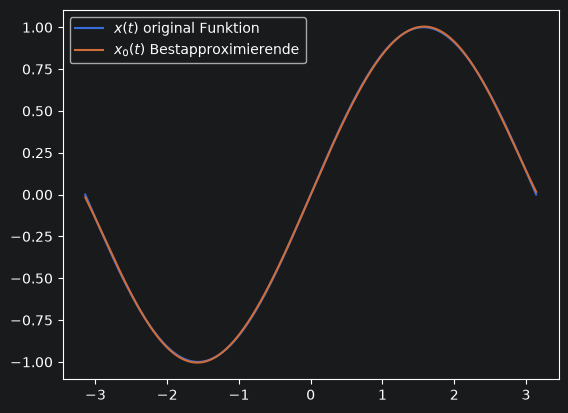

In [13]:
tp = np.linspace(-np.pi,np.pi,400)
plt.plot(tp,sp.lambdify(t,x(t))(tp),label='$x(t)$ original Funktion')
plt.plot(tp,sp.lambdify(t,expr)(tp),label='$x_0(t)$ Bestapproximierende')
plt.legend()
plt.show()

Mit einem Polynom 5. Grades kann der Sinus schon recht gut approximiert werden. Für den Fehler erhalten wir:

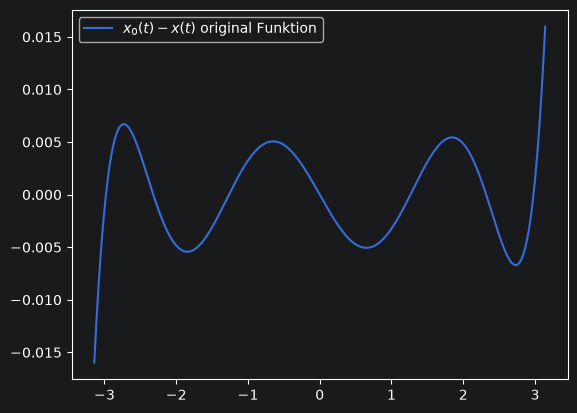

In [14]:
plt.plot(tp,sp.lambdify(t,expr)(tp)-sp.lambdify(t,x(t))(tp),label='$x_0(t)-x(t)$ original Funktion')
plt.legend()
plt.show()

## Benutzen der orthogonalen Basis aus dem Gramm-Schmidt Verfahren

Best approximierendes Element jedoch mit der orthogonaler Basis aus dem Gramm-Schmidt Verfahren:

(Legendre'sche Polynome)

In [15]:
ons = [1,
       t,
       1.5*t**2 - 0.5,
       2.5*t**3 - 1.5*t,
       4.375*t**4 - 3.75*t**2 + 0.375,
       7.875*t**5 - 8.75*t**3 + 1.875*t]

Kontrolle der Orthogonalität:

(Achtung, es wird nur die auf int reduzierte Matrix dargestellt, was in dem Fall ausreichend ist.)

In [16]:
m = []
for i in range(len(ons)):
    r = []
    for j in range(len(ons)):
        r.append(dot(ons[i],ons[j]))
    m.append(r)

np.array(np.round(np.array(m,dtype=float),0),dtype=int)

array([[      6,       0,      28,       0,     460,       0],
       [      0,      21,       0,     275,       0,    5763],
       [     28,       0,     246,       0,    4756,       0],
       [      0,     275,       0,    4522,       0,  103467],
       [    460,       0,    4756,       0,  100543,       0],
       [      0,    5763,       0,  103467,       0, 2492023]])

**Ups**: ist nicht orthogonal - warum??

$\Rightarrow$ **Vorsicht, der Definitionsbereich muss identisch sein!**

Die Orthogonalität wurde bezüglich dem Skalarprodukt auf dem Intervall $[0,1]$ kontruiert. Wir können die Basis skalieren:

In [17]:
ons=np.array([1, 
     1*t/pi,
     3/2*(t/pi)**2 - 1/2,
     5/2*(t/pi)**3 - 3/2*(t/pi),
     4375/1000*(t/pi)**4 - 375/100*(t/pi)**2 + 375/1000,
     7875/1000*(t/pi)**5 - 875/100*(t/pi)**3 + 1875/1000*(t/pi)])

In [18]:
m = []
for i in range(len(ons)):
    r = []
    for j in range(len(ons)):
        r.append(dot(ons[i],ons[j]))
    m.append(r)

np.round(np.array(m,dtype=float),3)

array([[6.283, 0.   , 0.   , 0.   , 0.   , 0.   ],
       [0.   , 2.094, 0.   , 0.   , 0.   , 0.   ],
       [0.   , 0.   , 1.257, 0.   , 0.   , 0.   ],
       [0.   , 0.   , 0.   , 0.898, 0.   , 0.   ],
       [0.   , 0.   , 0.   , 0.   , 0.698, 0.   ],
       [0.   , 0.   , 0.   , 0.   , 0.   , 0.571]])

## Aufgabe

Berechne für die orthogonale Basis die bestapproximierende für den Sinus aus!

In [19]:
lam2=[]
for o in ons:
    lam2.append(dot(x(t),o)/dot(o,o))
lam2=np.array(lam2)
lam2

array([0, 3/pi, 0, 3.5*(2.0 - 30.0/pi**2)/pi, 0,
       5.50000000000006*(-210.0/pi**2 + 2.0 + 1890.0/pi**4)/pi],
      dtype=object)

Die Koeffizienten der beiden Polynome sind unterschiedlich. Die finalen Polynome jedoch eindeutig und daher identisch, egal welche Basispolynome benutzt wurden. (Leider müssen wir an dieser Stelle auf `float` Zahlen zurückgreifen.)

In [20]:
expr2 = np.dot(lam2,ons)
expr2.evalf()

0.00564311797634701*t**5 - 0.155271410633431*t**3 + 0.987862135574679*t

Ausmultipliziert das erste Polynom:

In [21]:
expr.evalf()

0.00564311797634683*t**5 - 0.155271410633429*t**3 + 0.987862135574674*t

Graphische Darstellung der Lösung

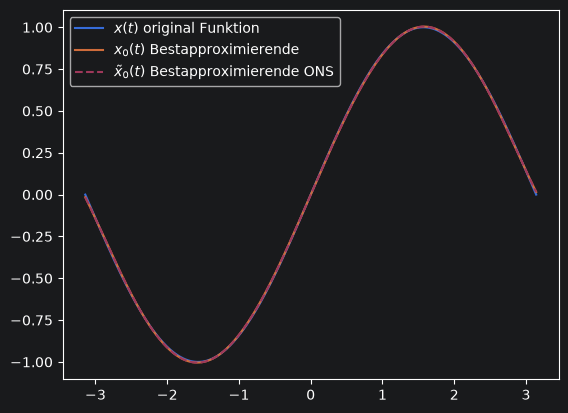

In [22]:
tp = np.linspace(-np.pi,np.pi,400)
plt.plot(tp,sp.lambdify(t,x(t))(tp),label='$x(t)$ original Funktion')
plt.plot(tp,sp.lambdify(t,expr)(tp),label='$x_0(t)$ Bestapproximierende')
plt.plot(tp,sp.lambdify(t,expr2)(tp),'--',label=r'$\tilde{x}_0(t)$ Bestapproximierende ONS')
plt.legend()
plt.show()